# 02 Pleiades membership with HDBSCAN (Gaia DR3)

Topic 01 Gaia, notebook 02. Written 2026-11-16.

**Goal.** Select the members of the Pleiades from Gaia DR3 astrometry alone, in a way we can defend: transparent feature space, documented parameters, a sensitivity check for binaries, a stability check against the Gaia measurement errors, and a comparison with the current reference catalogue (Hunt & Reffert). The member list is the input for notebook 03 (distance) and 04 (age).

**Decisions (from notebook 01 and the planning chat, 2026-11-15/16).**

| Topic | Decision |
|---|---|
| Binaries | No RUWE cut. All stars stay in; `probable_binary` = RUWE >= 1.4 is a flag. Membership is run with and without flagged stars (section 9). |
| Feature space | Main run in 5D: Galactic Cartesian position X, Y, Z [pc] and tangential velocity v_ra, v_dec [km/s], as Hunt & Reffert (2023) did for clusters closer than 150 pc. Comparison run in 3D: proper motions and parallax (section 7). |
| Sample volume | Sphere of 30 pc around the Pleiades centre (exercise: 20 and 40 pc). |
| HDBSCAN | `min_samples` = 10, `min_cluster_size` from {10, 20, 40, 80} (main run 40), `eom` selection, members need probability >= 0.5. All as in Hunt & Reffert (2023), except that the selection method is not stated there. |
| Stability | 50 to 100 redraws of parallax and proper motion within their Gaia errors (section 10). |
| Reference | Hunt & Reffert 2024 (VizieR J/A+A/686/A42, current version). Hunt & Reffert 2023 (J/A+A/673/A114, marked obsolete by CDS) only as fallback if the 2024 table has no tidal-radius flag. |
| Colour cuts | Only for the colour-magnitude diagram (section 12), never for membership. |

**Predictions, written down before the first run** (checked in section 13):

| Quantity | Prediction |
|---|---|
| Rows in the download | 50,000 to 100,000 |
| Stars in the 30 pc sphere | 5,000 to 10,000 |
| Pleiades members, 5D main run | 1,000 to 1,500 |
| Median distance of members | about 135 pc (no parallax zero-point correction yet) |
| Tangential speed of the cluster | about 32 km/s |
| Members flagged as probable binaries | 10 to 15 % |
| Unflagged stars that change status without the flagged ones | below 2 % |
| Agreement with Hunt & Reffert inside our sample (recall) | at least 90 % |
| Bright members (G < 18): proper motion vs distance | clearly negative correlation; tangential velocity vs distance close to zero |

**How to run.** Kernel "Astro (Python)", then Kernel, Restart Kernel and Run All Cells. The first run downloads two tables (Gaia, a few minutes; VizieR, seconds) into `data/raw/`. Later runs work offline. The redraws in section 10 take a few minutes.

**What to send back to Claude.** All printed tables (sections 2 to 12) and the PNG files in `figures/` with prefix `02_`.

## 1. Setup and parameters

Finds the project base folder (the one containing `shared/config.py`) by walking up from the notebook folder. All parameters you may change are collected in the second cell. Lines marked `EXERCISE` are the ones meant for experiments. After changing a parameter, run all cells again from the top.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from astropy.table import Table
from astropy.coordinates import SkyCoord
import astropy.units as u
import sklearn
from sklearn.cluster import HDBSCAN
from sklearn.preprocessing import RobustScaler
from scipy.stats import spearmanr

here = Path.cwd().resolve()
base = next(p for p in [here, *here.parents] if (p / "shared" / "config.py").exists())
if str(base / "shared") not in sys.path:
    sys.path.insert(0, str(base / "shared"))

import config
from gaia_tools import query_gaia_cached, bp_rp_excess_corrected, sigma_c_star, absolute_mag

PROJECT = config.project_dir("01_gaia")
FIG = PROJECT / "figures"

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
                     "axes.grid": False, "savefig.bbox": "tight"})
print("Base folder:", config.BASE)
print("Figures go to:", FIG)
print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__,
      "| scikit-learn", sklearn.__version__)

Base folder: H:\Astronomie
Figures go to: H:\Astronomie\projects\01_gaia\figures
numpy 2.2.6 | pandas 2.3.3 | matplotlib 3.10.9 | scikit-learn 1.7.2


In [2]:
# ---- Literature values, used only to place the sample and to recognise the cluster ----
PLEIADES_RA, PLEIADES_DEC = 56.75, 24.12   # deg (ICRS), cluster centre
PLEIADES_PLX = 7.364                        # mas   (Gaia Collaboration, Babusiaux et al. 2018, DR2)
PLEIADES_PM = (19.997, -45.548)             # mas/yr (same source)
PLEIADES_DIST = 1000.0 / PLEIADES_PLX       # pc, about 135.8

# ---- Query (server side). Changing these needs a new download (see section 2) ----
CONE_RADIUS_DEG = 25.0      # sky radius; large enough for spheres up to 40 pc
PLX_RANGE = (5.0, 12.0)     # mas, i.e. 83 to 200 pc
POE_MIN = 10                # parallax_over_error

# ---- Analysis (local). Change and re-run all cells ----
SPHERE_RADIUS = 30.0        # pc around the cluster centre.  EXERCISE: 20 and 40
RUWE_FLAG = 1.4             # probable_binary flag (no cut)
MIN_CLUSTER_SIZE = 40       # HDBSCAN.                        EXERCISE: 10, 20, 80
MIN_SAMPLES = 10            # HDBSCAN (Hunt & Reffert 2023).  EXERCISE: 5, 20
SELECTION = "eom"           # HDBSCAN cluster selection.      EXERCISE: "leaf"
PROB_MIN = 0.5              # membership probability threshold (Hunt & Reffert 2023)
N_DRAWS = 50                # redraws within Gaia errors.     Final run: 100
RNG_SEED = 2026             # makes the redraws reproducible

K = 4.740470                # km/s per (mas/yr x kpc): v [km/s] = K * mu [mas/yr] / parallax [mas]

## 2. Query Gaia DR3: a cone around the Pleiades (server-side filter, cached locally)

**What.** All Gaia DR3 sources within 25 deg of the cluster centre with parallax between 5 and 12 mas (83 to 200 pc) and `parallax_over_error >= 10`. Besides the columns of notebook 01 we ask for the three correlation coefficients between parallax and proper motions (needed for the redraws in section 10) and `ipd_frac_multi_peak` (a second binary indicator, stored for later, not used yet).

**Why so generous.** Section 3 cuts a sphere around the cluster out of this cone. The cone is sized so that spheres up to 40 pc fit without a new download: at the near side of a 40 pc sphere (96 pc) 40 pc spans almost 25 deg.

**Cost.** `parallax_over_error >= 10` removes, at 136 pc, roughly everything fainter than G of about 20, i.e. the lowest-mass members (late M dwarfs, brown dwarfs). Distance and age (notebooks 03 and 04) do not need them, but the comparison with Hunt & Reffert must take it into account (section 11).

**Analogy.** Like a read-length or base-quality filter applied at download time: cheaper to store, but it fixes which part of the population can be seen at all.

**Note.** The ESA archive may be unreachable; the query then goes to ARI Heidelberg or AIP Potsdam automatically (same catalogue). The cache file is only reused if the stored query text matches the current one.

In [3]:
ADQL = f'''
SELECT source_id, ra, dec, l, b,
       parallax, parallax_error, parallax_over_error,
       pmra, pmra_error, pmdec, pmdec_error,
       parallax_pmra_corr, parallax_pmdec_corr, pmra_pmdec_corr,
       ruwe, astrometric_params_solved, ipd_frac_multi_peak,
       phot_g_mean_mag, phot_bp_mean_mag, phot_rp_mean_mag, bp_rp,
       phot_g_mean_flux_over_error, phot_bp_mean_flux_over_error, phot_rp_mean_flux_over_error,
       phot_bp_rp_excess_factor,
       radial_velocity, radial_velocity_error
FROM gaiadr3.gaia_source
WHERE 1 = CONTAINS(POINT('ICRS', ra, dec), CIRCLE('ICRS', {PLEIADES_RA}, {PLEIADES_DEC}, {CONE_RADIUS_DEG}))
  AND parallax BETWEEN {PLX_RANGE[0]} AND {PLX_RANGE[1]}
  AND parallax_over_error >= {POE_MIN}
'''

RAW_FILE = config.RAW / "01-02_pleiades_cone_dr3.fits"
adql_file = RAW_FILE.with_suffix(".adql")
stale = RAW_FILE.exists() and adql_file.exists() and ADQL.strip() not in adql_file.read_text(encoding="utf-8")
if stale:
    print("The query parameters changed since the cached download. Downloading again.")
tab = query_gaia_cached(ADQL, RAW_FILE, overwrite=stale)

df = tab.to_pandas()
df.columns = [c.lower() for c in df.columns]
print(f"{len(df):,} sources downloaded or loaded")
print(adql_file.read_text(encoding="utf-8").splitlines()[0])   # which service answered

Loading cached result: H:\Astronomie\data\raw\01-02_pleiades_cone_dr3.fits
93,872 sources downloaded or loaded
-- service: ESA Gaia archive (https://gea.esac.esa.int/tap-server/tap)


## 3. Derived quantities, the sphere and the flags

**What.** For every star:
- distance d = 1000 / parallax [pc];
- position in Galactic Cartesian coordinates X, Y, Z [pc] (Sun at the origin; X towards the Galactic centre, Y in the direction of rotation, Z towards the north Galactic pole);
- tangential velocity v_ra = K * pmra / parallax and v_dec = K * pmdec / parallax [km/s], with K = 4.74. This converts an angular motion into a speed by multiplying with the distance;
- distance from the cluster centre in 3D, `r_centre` [pc].

Then we keep the stars with `r_centre <= SPHERE_RADIUS`. Two flag columns are added, nothing is removed: `probable_binary` (RUWE >= 1.4) and `six_param` (5 or 6 parameter solution; 6-parameter solutions estimate the colour from the astrometry itself and are less precise).

**Why a sphere and not the cone.** HDBSCAN finds a cluster as an overdensity relative to its surroundings. A cone is wider at the back than at the front, so at its edges the density drops for purely geometric reasons. A sphere gives the algorithm the same amount of field in all directions. 1/parallax is acceptable because the relative parallax error is at most 10 %.

**Cost.** The sphere uses measured distances. For bright stars (G < 18) the distance error is about 2 pc, for the faintest stars in our sample up to about 13 pc. Faint members are therefore smeared along the line of sight, and some fall out of the sphere or into it. The redraws in section 10 show how much this matters.

**Analogy.** A sampling design with reference sites evenly around the population, not only on one side.

**What to look for.** The check below prints whether the sphere fits into the cone and the parallax window. Taurus (a young star-forming region at 130 to 160 pc, 10 to 15 deg east of the Pleiades) lies at the edge of a 30 pc sphere and fully inside a 40 pc sphere. A second group there is real, not an error.

In [4]:
df["dist_pc"] = 1000.0 / df["parallax"]
df["v_ra"] = K * df["pmra"] / df["parallax"]
df["v_dec"] = K * df["pmdec"] / df["parallax"]
df["mu_tot"] = np.hypot(df["pmra"], df["pmdec"])
df["v_tan"] = np.hypot(df["v_ra"], df["v_dec"])
df["mg"] = absolute_mag(df["phot_g_mean_mag"], df["parallax"])

gal = SkyCoord(ra=df["ra"].to_numpy() * u.deg, dec=df["dec"].to_numpy() * u.deg,
               distance=df["dist_pc"].to_numpy() * u.pc, frame="icrs").galactic.cartesian
df["x"], df["y"], df["z"] = gal.x.to_value(u.pc), gal.y.to_value(u.pc), gal.z.to_value(u.pc)

c0 = SkyCoord(ra=PLEIADES_RA * u.deg, dec=PLEIADES_DEC * u.deg, distance=PLEIADES_DIST * u.pc,
              frame="icrs").galactic.cartesian
X0 = np.array([c0.x.to_value(u.pc), c0.y.to_value(u.pc), c0.z.to_value(u.pc)])
df["r_centre"] = np.sqrt((df["x"] - X0[0])**2 + (df["y"] - X0[1])**2 + (df["z"] - X0[2])**2)

df["probable_binary"] = df["ruwe"] >= RUWE_FLAG
df["six_param"] = df["astrometric_params_solved"] == 95

# Does the sphere fit into the downloaded cone and parallax window?
near, far = PLEIADES_DIST - SPHERE_RADIUS, PLEIADES_DIST + SPHERE_RADIUS
need_cone = np.degrees(np.arcsin(SPHERE_RADIUS / near))
print(f"Sphere {SPHERE_RADIUS:.0f} pc: distances {near:.0f} to {far:.0f} pc "
      f"(parallax {1000 / far:.2f} to {1000 / near:.2f} mas), needs a cone of {need_cone:.1f} deg")
ok = (need_cone <= CONE_RADIUS_DEG) and (1000 / far >= PLX_RANGE[0]) and (1000 / near <= PLX_RANGE[1])
print("Fits into the download:", "yes" if ok else "NO, enlarge the query in the parameter cell")

sph = df[df["r_centre"] <= SPHERE_RADIUS].reset_index(drop=True)
print(f"\nStars in the sphere: {len(sph):,} of {len(df):,} downloaded")
print(f"  flagged probable_binary (RUWE >= {RUWE_FLAG}): {sph['probable_binary'].sum():,} "
      f"({100 * sph['probable_binary'].mean():.1f} %)")
print(f"  six-parameter solutions: {sph['six_param'].sum():,} ({100 * sph['six_param'].mean():.1f} %)")
print(f"  G magnitude range: {sph['phot_g_mean_mag'].min():.1f} to {sph['phot_g_mean_mag'].max():.1f}")

Sphere 30 pc: distances 106 to 166 pc (parallax 6.03 to 9.45 mas), needs a cone of 16.5 deg
Fits into the download: yes

Stars in the sphere: 9,631 of 93,872 downloaded
  flagged probable_binary (RUWE >= 1.4): 1,389 (14.4 %)
  six-parameter solutions: 2,240 (23.3 %)
  G magnitude range: 3.5 to 20.5


## 4. Look first, then cluster

**What.** Four figures without any algorithm: (a) sky map of the sphere, (b) proper motions (vector point diagram), (c) total proper motion against distance and (d) tangential speed against distance, for stars near the cluster on the sky (within 3 deg) with proper motions within 10 mas/yr of the literature value.

**Why.** The Pleiades are visible by eye in (a) and (b). If the algorithm later disagrees with what we see, that is a warning sign. Panels (c) and (d) test the reason for the 5D feature space: a star at the front of the cluster has a larger proper motion than one at the back, although both move with the same speed. In (c) bright stars should therefore follow the dashed curve (same speed at every distance), in (d) a horizontal line.

**Cost.** None, nothing is removed. The selection for (c) and (d) uses a wide proper-motion window (10 mas/yr) so that it does not create the slope itself.

**Analogy.** Looking at QC plots and a PCA before running STRUCTURE.

**What to look for.** Bright stars (dark points) show the physical depth of the cluster: a slope in (c), flat in (d). Faint stars (light points) behave the other way round: their distance errors spread them horizontally, their proper motion stays, so they look flat in (c) and sloped in (d). This is the price of converting to speed: the parallax error enters the velocity.

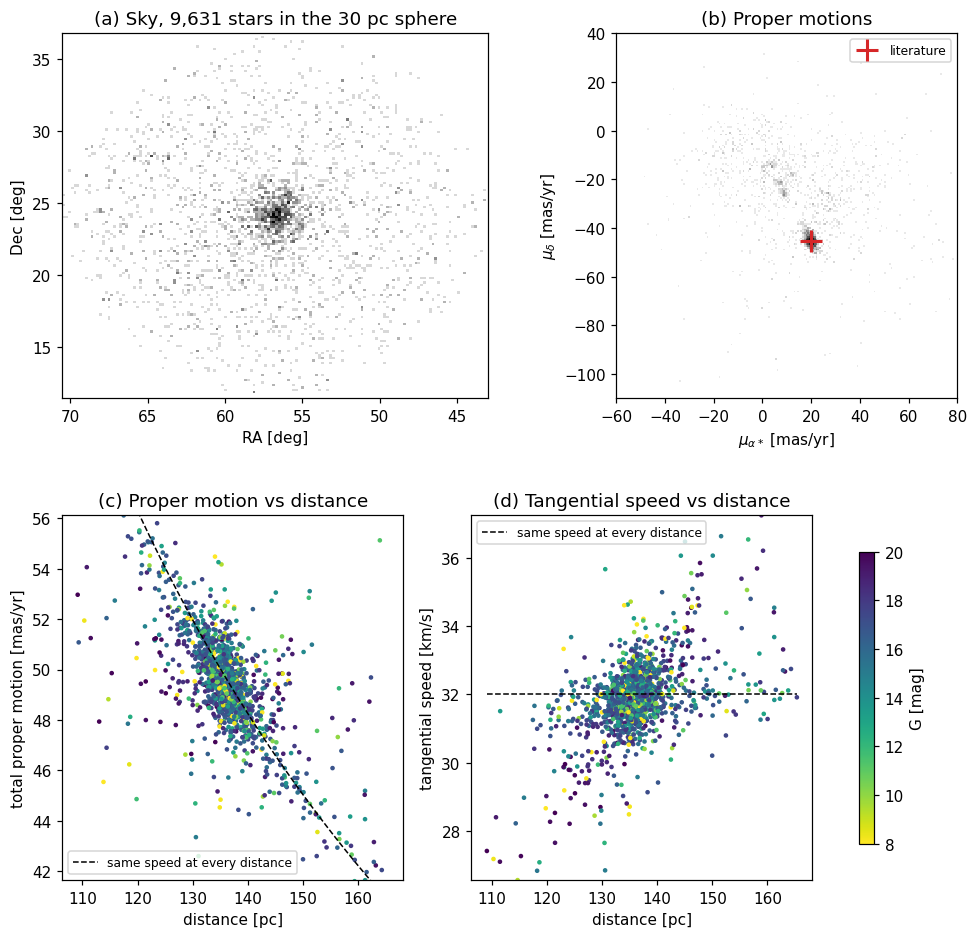

Expected cluster speed from literature values: 32.0 km/s
Stars near the cluster in panels (c) and (d): 1,394, of which G < 18: 1,208
Spearman correlation with distance, G < 18 within 15 pc of the centre distance:
  proper motion: -0.63   tangential speed: +0.32


In [5]:
v0 = K * np.hypot(*PLEIADES_PM) / PLEIADES_PLX       # expected tangential speed of the cluster [km/s]
sep = SkyCoord(sph["ra"].to_numpy() * u.deg, sph["dec"].to_numpy() * u.deg).separation(
    SkyCoord(PLEIADES_RA * u.deg, PLEIADES_DEC * u.deg)).deg
sph["sep_deg"] = sep
dpm = np.hypot(sph["pmra"] - PLEIADES_PM[0], sph["pmdec"] - PLEIADES_PM[1])
near_sel = sph[(sep < 3.0) & (dpm < 10.0)]
bright = near_sel[near_sel["phot_g_mean_mag"] < 18]

fig, axes = plt.subplots(2, 2, figsize=(11, 10), gridspec_kw={"hspace": 0.32})
ax = axes[0, 0]
ax.hist2d(sph["ra"], sph["dec"], bins=150, norm=LogNorm(), cmap="Greys", cmin=1)
ax.invert_xaxis(); ax.set_xlabel("RA [deg]"); ax.set_ylabel("Dec [deg]")
ax.set_title(f"(a) Sky, {len(sph):,} stars in the {SPHERE_RADIUS:.0f} pc sphere")

ax = axes[0, 1]
ax.hist2d(sph["pmra"], sph["pmdec"], bins=200, range=((-60, 80), (-110, 40)), norm=LogNorm(), cmap="Greys", cmin=1)
ax.plot(*PLEIADES_PM, "+", color="tab:red", ms=14, mew=2, label="literature")
ax.set_aspect("equal"); ax.legend(fontsize=8)
ax.set_xlabel(r"$\mu_{\alpha*}$ [mas/yr]"); ax.set_ylabel(r"$\mu_\delta$ [mas/yr]")
ax.set_title("(b) Proper motions")

d_grid = np.linspace(near_sel["dist_pc"].min(), near_sel["dist_pc"].max(), 100)
for ax, col, lab, curve in [(axes[1, 0], "mu_tot", "total proper motion [mas/yr]", 1000 * v0 / (K * d_grid)),
                            (axes[1, 1], "v_tan", "tangential speed [km/s]", np.full_like(d_grid, v0))]:
    sc = ax.scatter(near_sel["dist_pc"], near_sel[col], c=near_sel["phot_g_mean_mag"], s=4,
                    cmap="viridis_r", vmin=8, vmax=20)
    ax.plot(d_grid, curve, "k--", lw=1, label="same speed at every distance")
    ax.set_xlabel("distance [pc]"); ax.set_ylabel(lab); ax.legend(fontsize=8)
plt.colorbar(sc, ax=axes[1, :], label="G [mag]", shrink=0.8)
axes[1, 0].set_title("(c) Proper motion vs distance")
axes[1, 1].set_title("(d) Tangential speed vs distance")
axes[1, 0].set_ylim(np.nanpercentile(near_sel["mu_tot"], [0.5, 99.5]))
axes[1, 1].set_ylim(np.nanpercentile(near_sel["v_tan"], [0.5, 99.5]))
fig.savefig(FIG / "02_look_first.png")
plt.show()

core = (bright["dist_pc"] - PLEIADES_DIST).abs() < 15
rho_mu = spearmanr(bright.loc[core, "dist_pc"], bright.loc[core, "mu_tot"]).statistic
rho_v = spearmanr(bright.loc[core, "dist_pc"], bright.loc[core, "v_tan"]).statistic
print(f"Expected cluster speed from literature values: {v0:.1f} km/s")
print(f"Stars near the cluster in panels (c) and (d): {len(near_sel):,}, of which G < 18: {len(bright):,}")
print(f"Spearman correlation with distance, G < 18 within 15 pc of the centre distance:")
print(f"  proper motion: {rho_mu:+.2f}   tangential speed: {rho_v:+.2f}")

## 5. Feature space and scaling

**What.** Two feature spaces, each rescaled with `RobustScaler` so that every axis has median 0 and interquartile range 1 (as in Hunt & Reffert 2023):
- **5D (main run):** X, Y, Z [pc], v_ra, v_dec [km/s];
- **3D (comparison run):** pmra, pmdec [mas/yr], parallax [mas].

**Why scaling.** HDBSCAN measures distances between points. Without scaling, "1 pc" and "1 km/s" would be weighted against each other by the arbitrary choice of units. The robust version (median and interquartile range instead of mean and standard deviation) is not pulled around by outliers or by the cluster itself.

**Cost.** The scale of each axis is set by the spread of the *field* stars. A different sphere radius changes this spread and thus the relative weight of position and velocity. Second, a known limitation: the tangential velocities still contain a perspective effect. The cluster moves away from us at about 6 km/s, and towards the edge of the field a part of this motion appears in the tangential components. Inside the tidal radius this stays below 1 km/s, at the edge of a 30 pc sphere it reaches 1 to 2 km/s. Removing it fully would need radial velocities for all stars, which Gaia has only for bright ones.

**Analogy.** Standardising loci before a PCA: the choice decides which structure dominates.

**What to look for.** The printed interquartile ranges: they are the "unit" in which HDBSCAN measures. A cluster whose spread is much smaller than these units on every axis is easy to find.

In [6]:
FEAT_5D = ["x", "y", "z", "v_ra", "v_dec"]
FEAT_3D = ["pmra", "pmdec", "parallax"]

scaler_5d = RobustScaler().fit(sph[FEAT_5D].to_numpy())
scaler_3d = RobustScaler().fit(sph[FEAT_3D].to_numpy())
X5 = scaler_5d.transform(sph[FEAT_5D].to_numpy())
X3 = scaler_3d.transform(sph[FEAT_3D].to_numpy())

print("Interquartile range of each axis (the unit HDBSCAN measures in):")
print("  5D:", ", ".join(f"{f} {s:.1f}" for f, s in zip(FEAT_5D, scaler_5d.scale_)), "(pc and km/s)")
print("  3D:", ", ".join(f"{f} {s:.2f}" for f, s in zip(FEAT_3D, scaler_3d.scale_)), "(mas/yr and mas)")

Interquartile range of each axis (the unit HDBSCAN measures in):
  5D: x 17.3, y 17.3, z 17.0, v_ra 22.3, v_dec 21.2 (pc and km/s)
  3D: pmra 34.61, pmdec 33.12, parallax 0.94 (mas/yr and mas)


## 6. HDBSCAN, main run (5D)

**What.** HDBSCAN estimates a local density for every point (the *core distance* is the distance to its `min_samples`-th neighbour). From this it builds a tree of density levels and keeps the branches that stay stable over a wide range of densities. Everything else is labelled noise (label -1). Each point gets a label and a *membership probability*. The Pleiades are the cluster whose median proper motion and parallax are closest to the literature values; all other clusters are listed. Members are stars of that cluster with probability >= 0.5.

**Why HDBSCAN.** It copes with clusters of different density and needs no global distance threshold (unlike DBSCAN). Hunt & Reffert (2021) found it the most sensitive method for Gaia clusters, at the price of a high false-positive rate. That is less of a concern here, because we know which cluster we want.

**Cost.** The membership probability is not a statistical probability. It measures how deep a star sits in the dense core of its cluster and ignores the Gaia errors. 0.5 does not mean "a 50 % chance". Section 10 adds the error information.

**Analogy.** The condensed tree is a dendrogram like UPGMA, but cut adaptively instead of at one fixed distance. `min_samples` acts like a minimum read depth: a point needs enough neighbours to count as dense. `min_cluster_size` is the smallest group you would still call a population. The probability is closer to a "core-ness" score than to a STRUCTURE q-value, which comes from a model.

**What to look for.** One dominant cluster at the literature position and motion, with a compact distance distribution around 135 pc. Warning signs: the Pleiades split into several clusters, merge with the field, or the cluster list contains many large groups.

In [7]:
def run_hdbscan(X, mcs=MIN_CLUSTER_SIZE, ms=MIN_SAMPLES, method=SELECTION):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", FutureWarning)
        h = HDBSCAN(min_cluster_size=mcs, min_samples=ms, cluster_selection_method=method).fit(X)
    return h.labels_, h.probabilities_


def cluster_table(frame, labels, probs):
    rows = []
    for lab in np.unique(labels[labels >= 0]):
        m = labels == lab
        g = frame[m]
        rows.append(dict(label=lab, n=int(m.sum()), n_p50=int((probs[m] >= PROB_MIN).sum()),
                         ra=g["ra"].median(), dec=g["dec"].median(), dist=g["dist_pc"].median(),
                         pmra=g["pmra"].median(), pmdec=g["pmdec"].median(),
                         plx=g["parallax"].median(), v_ra=g["v_ra"].median(), v_dec=g["v_dec"].median()))
    t = pd.DataFrame(rows)
    if len(t):
        # distance from the literature values: proper motion in units of 2 mas/yr, parallax in 0.3 mas
        t["score"] = np.hypot(np.hypot(t["pmra"] - PLEIADES_PM[0], t["pmdec"] - PLEIADES_PM[1]) / 2.0,
                              (t["plx"] - PLEIADES_PLX) / 0.3)
        t = t.sort_values("n", ascending=False).reset_index(drop=True)
    return t


def pick_pleiades(table, max_score=3.0):
    # the largest cluster whose median motion and parallax match the literature (score < 3)
    if len(table) == 0:
        return None
    cand = table[table["score"] < max_score]
    return int(cand.loc[cand["n"].idxmax(), "label"]) if len(cand) else None


def jaccard(a, b):
    a, b = np.asarray(a, bool), np.asarray(b, bool)
    union = (a | b).sum()
    return (a & b).sum() / union if union else np.nan


t0 = time.time()
lab5, prob5 = run_hdbscan(X5)
tab5 = cluster_table(sph, lab5, prob5)
pl5 = pick_pleiades(tab5)
sph["lab_5d"], sph["prob_5d"] = lab5, prob5
sph["mem_5d"] = (lab5 == pl5) & (prob5 >= PROB_MIN) if pl5 is not None else False
print(f"HDBSCAN 5D: {time.time() - t0:.1f} s, {len(tab5)} clusters, {np.mean(lab5 == -1) * 100:.0f} % noise")
print(tab5.head(10).to_string(index=False, float_format=lambda v: f"{v:.2f}"))

m = sph["mem_5d"]
print(f"\nPleiades = label {pl5}: {int((lab5 == pl5).sum()):,} stars in the cluster, "
      f"{int(m.sum()):,} members with probability >= {PROB_MIN}")
print(f"Members: median distance {sph.loc[m, 'dist_pc'].median():.1f} pc, "
      f"median pm ({sph.loc[m, 'pmra'].median():.2f}, {sph.loc[m, 'pmdec'].median():.2f}) mas/yr, "
      f"median tangential speed {sph.loc[m, 'v_tan'].median():.1f} km/s")
print(f"Members: robust spread of distance {1.4826 * (sph.loc[m, 'dist_pc'] - sph.loc[m, 'dist_pc'].median()).abs().median():.1f} pc, "
      f"of v_ra {1.4826 * (sph.loc[m, 'v_ra'] - sph.loc[m, 'v_ra'].median()).abs().median():.2f} km/s, "
      f"of v_dec {1.4826 * (sph.loc[m, 'v_dec'] - sph.loc[m, 'v_dec'].median()).abs().median():.2f} km/s")

HDBSCAN 5D: 0.5 s, 3 clusters, 80 % noise
 label    n  n_p50    ra   dec   dist  pmra  pmdec  plx  v_ra  v_dec  score
     0 1744    880 56.63 24.11 135.81 19.89 -45.34 7.36 12.83 -29.12   0.12
     1  155    125 67.17 26.51 129.38  7.79 -22.78 7.73  4.76 -14.34  12.98
     2   53     53 62.47 20.41 121.60  3.80 -14.05 8.22  2.21  -8.11  17.94

Pleiades = label 0: 1,744 stars in the cluster, 880 members with probability >= 0.5
Members: median distance 135.6 pc, median pm (19.90, -45.45) mas/yr, median tangential speed 31.9 km/s
Members: robust spread of distance 2.6 pc, of v_ra 0.66 km/s, of v_dec 0.62 km/s


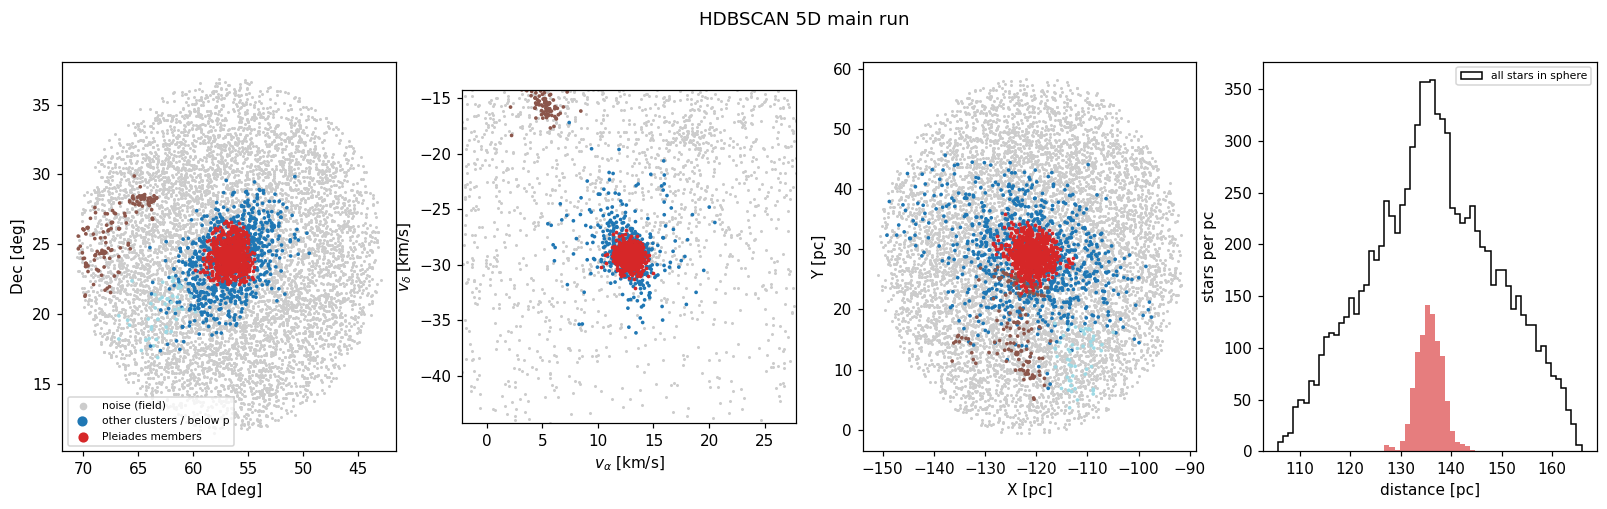

In [8]:
def membership_figure(frame, labels, members, title, fname):
    other = (labels >= 0) & ~members
    field = labels < 0
    fig, axes = plt.subplots(1, 4, figsize=(18, 4.6))
    panels = [("ra", "dec", "RA [deg]", "Dec [deg]"),
              ("v_ra", "v_dec", r"$v_{\alpha}$ [km/s]", r"$v_{\delta}$ [km/s]"),
              ("x", "y", "X [pc]", "Y [pc]")]
    for ax, (cx, cy, lx, ly) in zip(axes[:3], panels):
        ax.scatter(frame.loc[field, cx], frame.loc[field, cy], s=1, color="0.8", label="noise (field)")
        ax.scatter(frame.loc[other, cx], frame.loc[other, cy], s=2, c=labels[other], cmap="tab20",
                   label="other clusters / below p")
        ax.scatter(frame.loc[members, cx], frame.loc[members, cy], s=2, color="tab:red", label="Pleiades members")
        ax.set_xlabel(lx); ax.set_ylabel(ly)
    axes[0].invert_xaxis(); axes[0].legend(fontsize=7, markerscale=4, loc="lower left")
    vr = frame.loc[members, ["v_ra", "v_dec"]].median()
    axes[1].set_xlim(vr["v_ra"] - 15, vr["v_ra"] + 15); axes[1].set_ylim(vr["v_dec"] - 15, vr["v_dec"] + 15)
    axes[1].set_aspect("equal")
    ax = axes[3]
    bins = np.arange(PLEIADES_DIST - SPHERE_RADIUS, PLEIADES_DIST + SPHERE_RADIUS + 1, 1.0)
    ax.hist(frame.loc[members, "dist_pc"], bins=bins, histtype="stepfilled", alpha=0.6, color="tab:red")
    ax.hist(frame["dist_pc"], bins=bins, histtype="step", color="k", label="all stars in sphere")
    ax.set_xlabel("distance [pc]"); ax.set_ylabel("stars per pc"); ax.legend(fontsize=7)
    fig.suptitle(title)
    fig.savefig(FIG / fname)
    plt.show()


membership_figure(sph, lab5, sph["mem_5d"].to_numpy(), "HDBSCAN 5D main run", "02_hdbscan_5d.png")

## 7. Comparison run in 3D (proper motions and parallax)

**What.** The same HDBSCAN settings on proper motions and parallax, i.e. our original plan. Members of the two runs are compared star by star.

**Why.** It shows what the conversion to positions and speeds changes. In 3D the depth of the cluster appears as a diagonal streak (front stars: larger parallax and larger proper motion). In 5D the same stars sit at one speed, but faint stars get noisier positions and speeds.

**Cost.** The 3D space has no sky position at all: a group that moves like the Pleiades anywhere in the cone would be merged with them.

**What to look for.** In the printed table, where the stars found by only one run sit: at the front or back of the cluster (depth effect), at faint magnitudes (error effect) or far out on the sky (missing position information in 3D).

**Exercise.** Compare the Jaccard index (shared members divided by members of either run) with the values of the parameter scan in section 8.

HDBSCAN 3D: 6 clusters, Pleiades = label 4, 1,116 members
 label    n  n_p50    ra   dec   dist   pmra  pmdec  plx  v_ra  v_dec  score
     4 1756   1116 56.63 24.12 135.96  19.90 -45.30 7.36 12.86 -29.14   0.14
     2  249    249 64.67 26.24 133.09   8.38 -22.02 7.51  5.26 -14.03  13.13
     0   95     95 57.72 25.16 145.35 -12.12  -5.26 6.88 -8.45  -3.82  25.81
     3   78     78 62.78 21.24 123.43   3.46 -14.35 8.10  2.02  -8.29  17.82
     1   57     57 54.05 22.36 149.61  25.65 -25.66 6.68 18.01 -18.35  10.58

Jaccard index 5D vs 3D: 0.684
  group   n  median_dist  dist_minus_centre_abs  median_G  median_sep_deg  frac_binary_flag
   both 811       135.63                   1.63     15.92            1.01              0.08
5D only  69       135.85                   3.90     16.21            0.63              0.23
3D only 305       136.33                   3.65     16.54            2.85              0.06


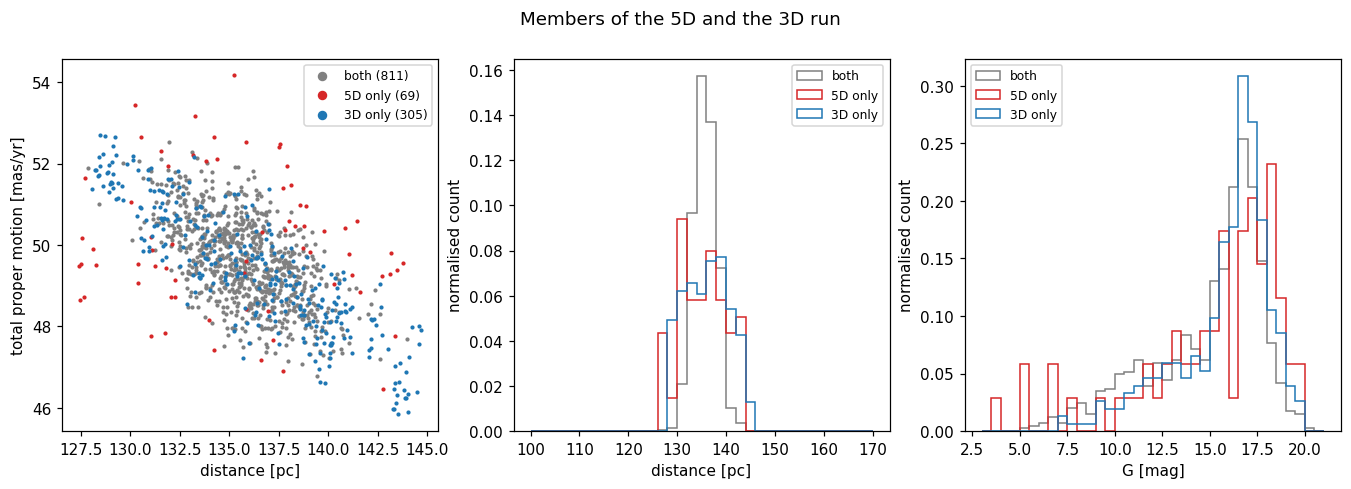

In [9]:
lab3, prob3 = run_hdbscan(X3)
tab3 = cluster_table(sph, lab3, prob3)
pl3 = pick_pleiades(tab3)
sph["lab_3d"], sph["prob_3d"] = lab3, prob3
sph["mem_3d"] = (lab3 == pl3) & (prob3 >= PROB_MIN) if pl3 is not None else False
print(f"HDBSCAN 3D: {len(tab3)} clusters, Pleiades = label {pl3}, {int(sph['mem_3d'].sum()):,} members")
print(tab3.head(5).to_string(index=False, float_format=lambda v: f"{v:.2f}"))

m5, m3 = sph["mem_5d"], sph["mem_3d"]
groups = {"both": m5 & m3, "5D only": m5 & ~m3, "3D only": m3 & ~m5}
rows = []
for name, g in groups.items():
    s = sph[g]
    rows.append(dict(group=name, n=int(g.sum()),
                     median_dist=s["dist_pc"].median(),
                     dist_minus_centre_abs=(s["dist_pc"] - PLEIADES_DIST).abs().median(),
                     median_G=s["phot_g_mean_mag"].median(),
                     median_sep_deg=s["sep_deg"].median(),
                     frac_binary_flag=s["probable_binary"].mean()))
print(f"\nJaccard index 5D vs 3D: {jaccard(m5, m3):.3f}")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.2f}"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
colors = {"both": "0.5", "5D only": "tab:red", "3D only": "tab:blue"}
for name, g in groups.items():
    axes[0].scatter(sph.loc[g, "dist_pc"], sph.loc[g, "mu_tot"], s=3, color=colors[name], label=f"{name} ({int(g.sum())})")
    axes[1].hist(sph.loc[g, "dist_pc"], bins=np.arange(100, 172, 2), histtype="step", color=colors[name], label=name, density=True)
    axes[2].hist(sph.loc[g, "phot_g_mean_mag"], bins=np.arange(3, 21.5, 0.5), histtype="step", color=colors[name], label=name, density=True)
axes[0].set_xlabel("distance [pc]"); axes[0].set_ylabel("total proper motion [mas/yr]"); axes[0].legend(fontsize=8, markerscale=3)
axes[1].set_xlabel("distance [pc]"); axes[1].set_ylabel("normalised count"); axes[1].legend(fontsize=8)
axes[2].set_xlabel("G [mag]"); axes[2].set_ylabel("normalised count"); axes[2].legend(fontsize=8)
fig.suptitle("Members of the 5D and the 3D run")
fig.savefig(FIG / "02_5d_vs_3d.png")
plt.show()

## 8. Parameter scan

**What.** The 5D run repeated for `min_cluster_size` in {10, 20, 40, 80} with both selection methods (`eom`, `leaf`), and for `min_samples` in {5, 10, 20}. For each run: number of clusters, number of Pleiades members and the Jaccard index with the main run.

**Why.** A membership list that changes a lot with arbitrary settings is not robust. Hunt & Reffert ran all four `min_cluster_size` values and kept the largest version of each cluster.

**Cost.** Only computing time (about one second per run for a 30 pc sphere).

**Analogy.** Like checking whether a population structure result survives different K values or different marker filters.

**What to look for.** Jaccard close to 1 for `eom`. `leaf` picks the tips of the tree and tends to cut the Pleiades into sub-clumps or to keep only the dense core; small `min_cluster_size` values produce many tiny clusters in the field (the known false positives of HDBSCAN).

In [10]:
scan = []
settings = [(mcs, MIN_SAMPLES, meth) for meth in ("eom", "leaf") for mcs in (10, 20, 40, 80)]
settings += [(MIN_CLUSTER_SIZE, ms, SELECTION) for ms in (5, 20)]
for mcs, ms, meth in settings:
    lab, prob = run_hdbscan(X5, mcs, ms, meth)
    t = cluster_table(sph, lab, prob)
    pl = pick_pleiades(t)
    mem = (lab == pl) & (prob >= PROB_MIN) if pl is not None else np.zeros(len(sph), bool)
    scan.append(dict(min_cluster_size=mcs, min_samples=ms, selection=meth, n_clusters=len(t),
                     pleiades_found=pl is not None, n_members=int(mem.sum()),
                     jaccard_vs_main=jaccard(mem, sph["mem_5d"])))
scan = pd.DataFrame(scan)
print(scan.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

 min_cluster_size  min_samples selection  n_clusters  pleiades_found  n_members  jaccard_vs_main
               10           10       eom          14            True       1437            0.612
               20           10       eom           6            True        853            0.969
               40           10       eom           3            True        880            1.000
               80           10       eom           2            True        906            0.971
               10           10      leaf          16            True         45            0.051
               20           10      leaf           6            True        853            0.969
               40           10      leaf           3            True        880            1.000
               80           10      leaf           2            True        906            0.971
               40            5       eom           5            True        880            0.934
               40           20

## 9. Sensitivity to binaries: with and without `probable_binary`

**What.** Run A is the main run (all stars). Run B uses the same settings on the sphere without the flagged stars (RUWE >= 1.4). Three numbers: the share of flagged stars among the members of A (compared with the field), how many unflagged stars change their status between A and B, and whether flagged members of A scatter more in velocity than unflagged ones.

**Why.** In an unresolved binary the light centre wobbles around the centre of mass. The measured proper motion is then biased and the star can drop out of the cluster. Conversely, high-RUWE stars could act as bridges between the cluster and the field.

**Cost.** None, nothing is deleted. That was the reason for the decision in notebook 01.

**Analogy.** Flagging loci with an excess of heterozygotes (possible paralogs) and running the structure analysis with and without them.

**What to look for.** Prediction: 10 to 15 % of the members flagged (less than the 28 % in notebook 01, because the RUWE test loses power with distance), fewer than 2 % of unflagged stars changing status, and a larger velocity scatter of the flagged members. A large number of status changes would mean that the binaries shape the cluster boundary.

Run A (all stars): 880 members, of which flagged: 77 (8.8 %); flagged share in the field: 15.0 %
Run B (flagged stars removed): 777 members
Unflagged stars: members in both 775, only in A 28, only in B 2  ->  status change 3.7 % of the unflagged members of A

Velocity offset from the cluster median (km/s):
     sample  flagged   n  median_dv_kms  p90_dv_kms
all members    False 803           0.74        1.30
all members     True  77           1.03        1.63
     G < 18    False 726           0.72        1.26
     G < 18     True  76           1.03        1.60


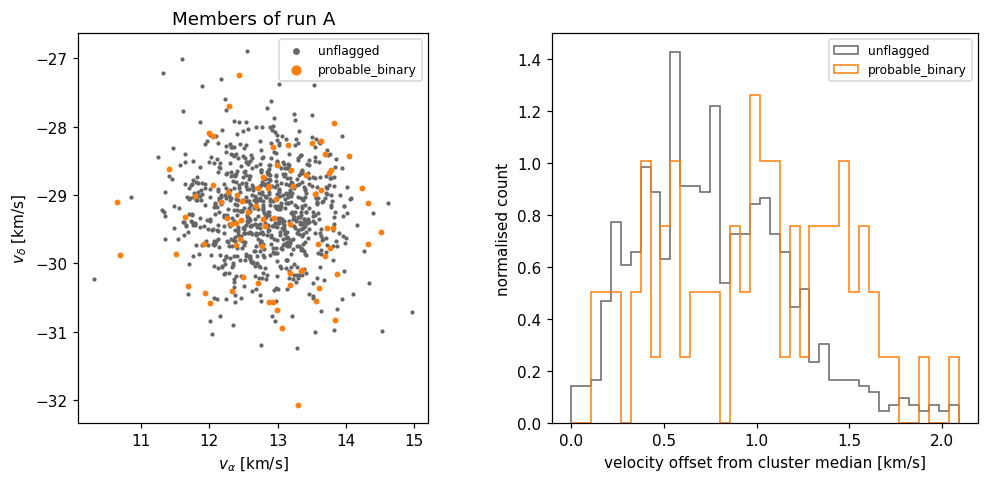

In [11]:
keepB = ~sph["probable_binary"].to_numpy()
XB = RobustScaler().fit_transform(sph.loc[keepB, FEAT_5D].to_numpy())
labB, probB = run_hdbscan(XB)
tabB = cluster_table(sph[keepB].reset_index(drop=True), labB, probB)
plB = pick_pleiades(tabB)
memB = np.zeros(len(sph), bool)
if plB is not None:
    memB[np.flatnonzero(keepB)] = (labB == plB) & (probB >= PROB_MIN)
sph["mem_5d_noflag"] = memB

A = sph["mem_5d"].to_numpy()
flag = sph["probable_binary"].to_numpy()
print(f"Run A (all stars): {A.sum():,} members, of which flagged: {(A & flag).sum():,} "
      f"({100 * flag[A].mean():.1f} %); flagged share in the field: {100 * flag[~A].mean():.1f} %")
print(f"Run B (flagged stars removed): {memB.sum():,} members")
u_ = ~flag
print(f"Unflagged stars: members in both {(A & memB & u_).sum():,}, only in A {(A & ~memB & u_).sum():,}, "
      f"only in B {(~A & memB & u_).sum():,}  ->  status change "
      f"{100 * ((A ^ memB) & u_).sum() / max((A & u_).sum(), 1):.1f} % of the unflagged members of A")

mem = sph[A].copy()
mem["dv"] = np.hypot(mem["v_ra"] - mem["v_ra"].median(), mem["v_dec"] - mem["v_dec"].median())
rows = []
for sel_name, sel in [("all members", np.ones(len(mem), bool)), ("G < 18", (mem["phot_g_mean_mag"] < 18).to_numpy())]:
    for fl in (False, True):
        s = mem[sel & (mem["probable_binary"].to_numpy() == fl)]
        rows.append(dict(sample=sel_name, flagged=fl, n=len(s), median_dv_kms=s["dv"].median(),
                         p90_dv_kms=s["dv"].quantile(0.9)))
print("\nVelocity offset from the cluster median (km/s):")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.2f}"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
ax = axes[0]
ax.scatter(mem.loc[~mem["probable_binary"], "v_ra"], mem.loc[~mem["probable_binary"], "v_dec"], s=3, color="0.4", label="unflagged")
ax.scatter(mem.loc[mem["probable_binary"], "v_ra"], mem.loc[mem["probable_binary"], "v_dec"], s=8, color="tab:orange", label="probable_binary")
ax.set_aspect("equal"); ax.legend(fontsize=8, markerscale=2)
ax.set_xlabel(r"$v_{\alpha}$ [km/s]"); ax.set_ylabel(r"$v_{\delta}$ [km/s]"); ax.set_title("Members of run A")
ax = axes[1]
bins = np.linspace(0, np.nanpercentile(mem["dv"], 99), 40)
ax.hist(mem.loc[~mem["probable_binary"], "dv"], bins=bins, histtype="step", density=True, color="0.4", label="unflagged")
ax.hist(mem.loc[mem["probable_binary"], "dv"], bins=bins, histtype="step", density=True, color="tab:orange", label="probable_binary")
ax.set_xlabel("velocity offset from cluster median [km/s]"); ax.set_ylabel("normalised count"); ax.legend(fontsize=8)
fig.savefig(FIG / "02_ruwe_sensitivity.png")
plt.show()

## 10. Stability within the Gaia errors (redraws)

**What.** For every star, parallax and both proper motions are drawn again from a three-dimensional normal distribution with the Gaia errors and correlation coefficients as covariance. Distance, position and velocity are recomputed, the same scaling as in the main run is applied, and HDBSCAN runs again. This is repeated `N_DRAWS` times. In each draw the Pleiades are the cluster that overlaps most with the main-run members. `freq_5d` is the fraction of draws in which a star is a member.

**Why.** It adds what the HDBSCAN probability lacks: the measurement uncertainty. Positions on the sky are kept fixed (their errors are below 1 mas, negligible here), and the star sample stays the same in every draw (we do not re-cut the sphere).

**Cost.** Computing time only: about `N_DRAWS` times one HDBSCAN run.

**Analogy.** Bootstrap support for nodes of a phylogenetic tree: how often does a star end up in the same group when the data are perturbed within their uncertainty?

**What to look for.** Bright members should have frequencies close to 1. Stars with a high HDBSCAN probability but a low frequency are typically faint stars near the edge: their membership depends on noise. Warning sign: many bright stars with low frequency, which would point to an unstable clustering rather than to measurement errors.

**Exercise.** Run with `N_DRAWS = 100` and check whether the frequency table changes.

first draw took 0.5 s; expected total about 0.4 min
50 draws in 0.4 min; Pleiades recovered in 50 draws

Redraw frequency vs membership in the main run:
mem_5d      member (main run)  not a member
freq_5d                                    
< 0.5                      34          8734
0.5 to 0.9                161            17
>= 0.9                    685             0

Members with G < 18 and frequency < 0.5: 21
Members with G >= 18 and frequency < 0.5: 13


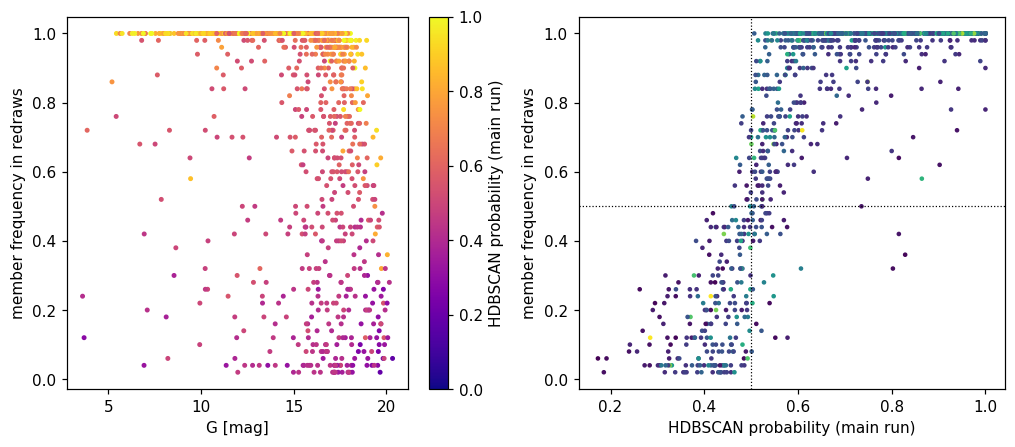

In [12]:
rng = np.random.default_rng(RNG_SEED)
n = len(sph)
mean = sph[["parallax", "pmra", "pmdec"]].to_numpy()
err = sph[["parallax_error", "pmra_error", "pmdec_error"]].to_numpy()
r_pa = sph["parallax_pmra_corr"].fillna(0).to_numpy()
r_pd = sph["parallax_pmdec_corr"].fillna(0).to_numpy()
r_md = sph["pmra_pmdec_corr"].fillna(0).to_numpy()
corr = np.zeros((n, 3, 3))
corr[:, 0, 0] = corr[:, 1, 1] = corr[:, 2, 2] = 1.0
corr[:, 0, 1] = corr[:, 1, 0] = r_pa
corr[:, 0, 2] = corr[:, 2, 0] = r_pd
corr[:, 1, 2] = corr[:, 2, 1] = r_md
cov = err[:, :, None] * corr * err[:, None, :]
L = np.linalg.cholesky(cov + 1e-12 * np.eye(3))   # tiny jitter guards against rounding
unit = sph[["x", "y", "z"]].to_numpy() / sph["dist_pc"].to_numpy()[:, None]   # direction to each star
ref = sph["mem_5d"].to_numpy()

counts = np.zeros(n)
found = 0
t0 = time.time()
for i in range(N_DRAWS):
    plx, pmra, pmdec = (mean + np.einsum("nij,nj->ni", L, rng.standard_normal((n, 3)))).T
    d = 1000.0 / plx
    feats = np.column_stack([unit * d[:, None], K * pmra / plx, K * pmdec / plx])
    lab, prob = run_hdbscan(scaler_5d.transform(feats))
    best, best_j = None, 0.0
    for l in np.unique(lab[lab >= 0]):
        j = jaccard(lab == l, ref)
        if j > best_j:
            best, best_j = l, j
    if best is not None and best_j > 0.3:
        counts += (lab == best) & (prob >= PROB_MIN)
        found += 1
    if i == 0:
        print(f"first draw took {time.time() - t0:.1f} s; expected total about {(time.time() - t0) * N_DRAWS / 60:.1f} min")
print(f"{N_DRAWS} draws in {(time.time() - t0) / 60:.1f} min; Pleiades recovered in {found} draws")
sph["freq_5d"] = counts / max(found, 1)

mem = sph["mem_5d"]
bins_f = [0, 0.5, 0.9, 1.01]
tbl = pd.crosstab(pd.cut(sph["freq_5d"], bins_f, right=False, labels=["< 0.5", "0.5 to 0.9", ">= 0.9"]),
                  mem.map({True: "member (main run)", False: "not a member"}))
print("\nRedraw frequency vs membership in the main run:")
print(tbl.to_string())
bright = sph["phot_g_mean_mag"] < 18
print(f"\nMembers with G < 18 and frequency < 0.5: {int((mem & bright & (sph['freq_5d'] < 0.5)).sum())}")
print(f"Members with G >= 18 and frequency < 0.5: {int((mem & ~bright & (sph['freq_5d'] < 0.5)).sum())}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
s = sph[(sph["freq_5d"] > 0) | mem]
sc = axes[0].scatter(s["phot_g_mean_mag"], s["freq_5d"], c=s["prob_5d"], s=5, cmap="plasma", vmin=0, vmax=1)
plt.colorbar(sc, ax=axes[0], label="HDBSCAN probability (main run)")
axes[0].set_xlabel("G [mag]"); axes[0].set_ylabel("member frequency in redraws")
axes[1].scatter(s["prob_5d"], s["freq_5d"], s=4, c=s["phot_g_mean_mag"], cmap="viridis_r")
axes[1].axvline(PROB_MIN, color="k", lw=0.8, ls=":"); axes[1].axhline(0.5, color="k", lw=0.8, ls=":")
axes[1].set_xlabel("HDBSCAN probability (main run)"); axes[1].set_ylabel("member frequency in redraws")
fig.savefig(FIG / "02_redraws.png")
plt.show()

## 11. Comparison with Hunt & Reffert

**What.** The Pleiades members of Hunt & Reffert are fetched from VizieR (TAP service, filtered on the server) and cached in `data/raw/01-02_hunt_reffert_pleiades.fits`. The code first reads the column list of the table, prints it and picks the columns it needs (cluster name, Gaia DR3 source ID, probability and the two flags `inrt` = inside the King tidal radius r_t and `inrj` = inside the Jacobi radius r_J; the 2024 table has both). It tries the current version (2024) first and falls back to 2023 if there is no tidal-radius flag. The Pleiades are the cluster with the most members within 2 deg of the centre. Matching is exact via the Gaia DR3 `source_id`, no positional crossmatch.

The comparison runs only inside the *common domain*: Hunt & Reffert members that passed our query and lie inside our sphere. First a funnel shows where the other ones were lost. Then a four-field table (both, only us, only them) for the 5D and the 3D run, once against all of their members and once against those inside their Jacobi radius r_J and inside r_t.

**Why the common domain.** Otherwise we would count stars as "missed" that we never downloaded by design (faint stars, tidal tails beyond 30 pc).

**Cost.** Hunt & Reffert are not the truth, they are a second method (also HDBSCAN, with a quality cut on the Rybizki et al. 2022 flag instead of a parallax precision cut, and Bailer-Jones distances instead of 1/parallax).

**Analogy.** Variant calls against a reference set, evaluated only in the high-confidence regions: recall = shared / theirs, agreement = shared / ours.

**What to look for.** Prediction: recall at least 90 % inside the domain, higher against the members inside r_t or r_J than against all of them. Stars only we have should sit at the edge or have low probability; stars only they have should be faint or near our probability threshold.

**If no VizieR server is reachable from your network** (as on 2026-11-18 for the CDS server): the code tries four servers and prints what failed. If TAP fails for all servers, the notebook automatically tries a second route through the VizieR web interface of the mirrors (CDS, CfA Harvard, NAOJ), which does not use TAP. Connection test per server in the command prompt: `powershell Test-NetConnection vizier.cfa.harvard.edu -Port 443` (`TcpTestSucceeded : True` means reachable). If none works, tell Claude; the fallback is a manual download of the Melotte_22 members from the VizieR web page, saved as `data/raw/01-02_hunt_reffert_pleiades.fits`. Everything after the download works from that file.

**If the download picks the wrong columns.** The printed column list shows what is there. Set `HR_COLUMNS` in the next cell by hand (for example `{"rt_flag": "InRt"}`), delete the cached file and run again.

In [13]:
import pyvo

# VizieR is mirrored at several data centres (identical tables). Tried in this order; a server that does
# not accept a TCP connection within 8 s is skipped, so a blocked server costs seconds, not minutes.
TAP_ENDPOINTS = [
    "https://tapvizier.cds.unistra.fr/TAPVizieR/tap",     # CDS Strasbourg
    "https://tapvizier1.cds.unistra.fr/TAPVizieR/tap",    # second CDS host name
    "https://vizier.cfa.harvard.edu/TAPVizieR/tap",       # CfA Harvard, USA
    "http://tapvizier.u-strasbg.fr/TAPVizieR/tap",        # old CDS domain
]
HR_CATALOGUES = [("Hunt & Reffert 2024", "J/A+A/686/A42/members"),
                 ("Hunt & Reffert 2023", "J/A+A/673/A114/members")]
HR_COLUMNS = {}            # manual override, keys: name, source_id, prob, rt_flag, ra, dec, gmag, plx
HR_FILE = config.RAW / "01-02_hunt_reffert_pleiades.fits"


def _pick(cols, test):
    hits = [r["column_name"] for _, r in cols.iterrows() if test(r)]
    return hits[0] if hits else None


def detect_columns(cols):
    low = lambda r: str(r["column_name"]).lower()
    desc = lambda r: str(r["description"]).lower()
    ucd = lambda r: str(r["ucd"]).lower()
    found = {
        "ra": _pick(cols, lambda r: "pos.eq.ra" in ucd(r) and "meta.main" in ucd(r)) or _pick(cols, lambda r: "pos.eq.ra" in ucd(r))
              or _pick(cols, lambda r: low(r) in ("ra_icrs", "raj2000", "ra")),
        "dec": _pick(cols, lambda r: "pos.eq.dec" in ucd(r) and "meta.main" in ucd(r)) or _pick(cols, lambda r: "pos.eq.dec" in ucd(r))
               or _pick(cols, lambda r: low(r) in ("de_icrs", "dej2000", "dec", "de")),
        "source_id": _pick(cols, lambda r: low(r) in ("gaiadr3", "gaia_dr3", "source_id", "source", "dr3name"))
                     or _pick(cols, lambda r: ("source_id" in desc(r) or "gaia dr3" in desc(r))
                              and str(r["datatype"]).lower() in ("long", "bigint", "int64")),
        "name": _pick(cols, lambda r: low(r) == "name") or _pick(cols, lambda r: "cluster" in desc(r) and "name" in desc(r)),
        "prob": _pick(cols, lambda r: "prob" in low(r)),
        "rt_flag": _pick(cols, lambda r: low(r) in ("inrt", "in_rt", "rt_flag"))
                   or _pick(cols, lambda r: ("tidal" in desc(r) or "king" in desc(r)) and "prob" not in low(r)
                            and str(r["datatype"]).lower() not in ("double", "float", "real")),
        "rj_flag": _pick(cols, lambda r: low(r) in ("inrj", "in_rj", "rj_flag"))
                   or _pick(cols, lambda r: "jacobi" in desc(r) and "prob" not in low(r)
                            and str(r["datatype"]).lower() not in ("double", "float", "real")),
        "gmag": _pick(cols, lambda r: low(r) in ("gmag", "phot_g_mean_mag")),
        "plx": _pick(cols, lambda r: low(r) in ("plx", "parallax")),
    }
    found.update(HR_COLUMNS)
    return found


TAP_USED = {"url": None}


def _reachable(url, timeout=8.0):
    import socket
    from urllib.parse import urlparse
    p = urlparse(url)
    try:
        with socket.create_connection((p.hostname, p.port or (443 if p.scheme == "https" else 80)), timeout=timeout):
            return True
    except OSError:
        return False


def run_tap(query, maxrec=None):
    # Runs a synchronous TAP query on the first VizieR server that answers, and remembers that server.
    errors = []
    urls = ([TAP_USED["url"]] if TAP_USED["url"] else []) + [e for e in TAP_ENDPOINTS if e != TAP_USED["url"]]
    for url in urls:
        if not _reachable(url):
            errors.append(f"{url}: no connection within 8 s")
            continue
        try:
            res = pyvo.dal.TAPService(url).run_sync(query, maxrec=maxrec)
            TAP_USED["url"] = url
            return res
        except Exception as exc:                                  # try the next server
            errors.append(f"{url}: {type(exc).__name__}: {str(exc)[:120]}")
    raise RuntimeError("No VizieR server answered:\n  " + "\n  ".join(errors) + "\n"
                       "See the note in section 11 for the manual route.")


AQ_SERVERS = ["vizier.cds.unistra.fr", "vizier.cfa.harvard.edu", "vizier.nao.ac.jp"]   # VizieR web interface, not TAP


def _aq_columns(tab):
    rows = []
    for nm in tab.colnames:
        col = tab[nm]
        kind = getattr(col.dtype, "kind", "O")
        rows.append(dict(column_name=nm, datatype={"i": "long", "u": "long", "f": "double", "b": "boolean"}.get(kind, "char"),
                         unit=str(col.unit or ""), ucd=str(col.meta.get("ucd", "")), description=str(col.description or "")))
    return pd.DataFrame(rows)


def _aq_array(col):
    kind = col.dtype.kind
    if kind == "u":
        return np.ma.filled(col, 0).astype("int64")
    if kind == "i":
        return np.ma.filled(col, -1).astype("int64")
    if kind == "f":
        return np.ma.filled(col.astype(float), np.nan)
    if kind == "b":
        return np.ma.filled(col, False)
    return np.array([str(x).strip() for x in np.ma.filled(col, "")])


def fetch_via_astroquery():
    # Second route: astroquery talks to the VizieR web interface of a mirror (works where TAP is blocked).
    from astroquery.vizier import Vizier
    centre = SkyCoord(PLEIADES_RA * u.deg, PLEIADES_DEC * u.deg)
    errors = []
    for server in AQ_SERVERS:
        if not _reachable("https://" + server):
            errors.append(f"{server}: no connection within 8 s")
            continue
        try:
            for label, table in HR_CATALOGUES:
                v = Vizier(vizier_server=server, columns=["**"], row_limit=-1)
                v.TIMEOUT = 180
                res = v.query_region(centre, radius=1 * u.deg, catalog=table)
                if len(res) == 0:
                    print(f"{server}: {label} ({table}) returned nothing, trying the next catalogue")
                    continue
                sample = res[0]
                cols = _aq_columns(sample)
                print(f"{server}: {label} ({table}), {len(cols)} columns")
                print(cols[["column_name", "unit", "description"]].to_string(index=False, max_colwidth=70))
                c = detect_columns(cols)
                print("Detected:", c)
                missing = [k for k in ("name", "source_id", "ra", "dec") if not c.get(k)]
                if missing:
                    raise RuntimeError(f"Columns not found: {missing}. Set HR_COLUMNS by hand.")
                if not c.get("rt_flag") and table != HR_CATALOGUES[-1][1]:
                    print(f"{label}: no tidal-radius flag found, falling back to the next catalogue\n")
                    continue
                names = pd.Series(_aq_array(sample[c["name"]]))
                top = names.value_counts()
                print("\nClusters within 1 deg of the centre:\n", top.head().to_string())
                name = str(top.index[0]).strip()
                sel = {"hr_cluster": c["name"], "source_id": c["source_id"], "hr_ra": c["ra"], "hr_dec": c["dec"]}
                for key, new in [("prob", "hr_prob"), ("rt_flag", "hr_in_rt"), ("rj_flag", "hr_in_rj"), ("gmag", "hr_gmag"), ("plx", "hr_plx")]:
                    if c.get(key):
                        sel[new] = c[key]
                need = sorted(set(sel.values()))
                vm = Vizier(vizier_server=server, columns=need, row_limit=-1)
                vm.TIMEOUT = 300
                how = "query_constraints"
                try:
                    r = vm.query_constraints(catalog=table, **{c["name"]: name})
                    mem = r[0] if len(r) else None
                except Exception as exc:
                    print("query_constraints failed:", type(exc).__name__, str(exc)[:100])
                    mem = None
                if mem is None or len(mem) == 0:
                    how = f"query_region radius {CONE_RADIUS_DEG + 2:.0f} deg, filtered locally"
                    r = vm.query_region(centre, radius=(CONE_RADIUS_DEG + 2) * u.deg, catalog=table)
                    mem = r[0]
                    keep = np.array([str(x).strip() == name for x in np.ma.filled(mem[c["name"]], "")])
                    mem = mem[keep]
                if mem[c["source_id"]].dtype.kind not in "iu":
                    raise RuntimeError("source_id arrived as a non-integer column (precision would be lost). "
                                       "Tell Claude, or use the manual route.")
                hr = Table({new: _aq_array(mem[old]) for new, old in sel.items()})
                hr.meta = {"HRCAT": table, "HRLABEL": label, "HRNAME": name}
                hr.write(HR_FILE, overwrite=True)
                stamp = time.strftime("%Y-%m-%dT%H:%M:%S")
                HR_FILE.with_suffix(".adql").write_text(
                    f"-- service: VizieR web interface via astroquery ({server}), TAP was not reachable\n"
                    f"-- retrieved: {stamp}\n-- catalogue: {label}, {table}\n-- cluster: {name}\n-- rows: {len(hr)}\n"
                    f"-- method: {how}; columns: {need}\n", encoding="utf-8")
                print(f"\nSaved {len(hr)} members of {name} ({label}, {how}) to {HR_FILE}")
                return hr
        except Exception as exc:
            errors.append(f"{server}: {type(exc).__name__}: {str(exc)[:150]}")
    raise RuntimeError("No VizieR server answered the astroquery route either:\n  " + "\n  ".join(errors))


def fetch_hunt_reffert():
    for label, table in HR_CATALOGUES:
        cols = run_tap("SELECT column_name, datatype, unit, ucd, description FROM TAP_SCHEMA.columns "
                       f"WHERE table_name = '{table}'").to_table().to_pandas()
        if len(cols) == 0:
            print(f"{label}: table {table} not found, trying the next one")
            continue
        print(f"{label} ({table}): {len(cols)} columns")
        print(cols[["column_name", "unit", "description"]].to_string(index=False, max_colwidth=70))
        c = detect_columns(cols)
        print("Detected:", c)
        missing = [k for k in ("name", "source_id", "ra", "dec") if not c.get(k)]
        if missing:
            raise RuntimeError(f"Columns not found: {missing}. Set HR_COLUMNS by hand.")
        if not c.get("rt_flag") and table != HR_CATALOGUES[-1][1]:
            print(f"{label}: no tidal-radius flag found, falling back to the next catalogue\n")
            continue
        # 1) which cluster dominates the centre?
        q1 = (f'SELECT "{c["name"]}" AS cl, COUNT(*) AS n FROM "{table}" '
              f"WHERE 1 = CONTAINS(POINT('ICRS', \"{c['ra']}\", \"{c['dec']}\"), CIRCLE('ICRS', {PLEIADES_RA}, {PLEIADES_DEC}, 2)) "
              f'GROUP BY "{c["name"]}"')
        top = run_tap(q1).to_table().to_pandas().sort_values("n", ascending=False)
        print("\nClusters within 2 deg of the centre:\n", top.head().to_string(index=False))
        name = str(top.iloc[0]["cl"]).strip()
        # 2) all members of that cluster
        sel = {"hr_cluster": c["name"], "source_id": c["source_id"], "hr_ra": c["ra"], "hr_dec": c["dec"]}
        for key, new in [("prob", "hr_prob"), ("rt_flag", "hr_in_rt"), ("rj_flag", "hr_in_rj"), ("gmag", "hr_gmag"), ("plx", "hr_plx")]:
            if c.get(key):
                sel[new] = c[key]
        cols_sql = ", ".join(f'"{v}" AS {k}' for k, v in sel.items())
        name_sql = name.replace("'", "''")
        q2 = f'SELECT {cols_sql} FROM "{table}" WHERE "{c["name"]}" = \'{name_sql}\''
        hr = run_tap(q2, maxrec=100_000).to_table()
        hr.meta = {"HRCAT": table, "HRLABEL": label, "HRNAME": name}
        hr.write(HR_FILE, overwrite=True)
        stamp = time.strftime("%Y-%m-%dT%H:%M:%S")
        HR_FILE.with_suffix(".adql").write_text(
            f"-- service: VizieR TAP ({TAP_USED['url']})\n-- retrieved: {stamp}\n-- catalogue: {label}, {table}\n"
            f"-- cluster: {name}\n-- rows: {len(hr)}\n-- step 1:\n{q1}\n-- step 2:\n{q2}\n", encoding="utf-8")
        print(f"\nSaved {len(hr)} members of {name} ({label}) to {HR_FILE}")
        return hr
    raise RuntimeError("No Hunt & Reffert table could be used.")


if HR_FILE.exists():
    hr_tab = Table.read(HR_FILE)
    print(f"Loading cached result: {HR_FILE}")
else:
    try:
        hr_tab = fetch_hunt_reffert()
    except RuntimeError as exc:
        if "No VizieR server answered" not in str(exc):
            raise
        print("TAP is not reachable from here:\n", exc, "\n\nSwitching to the astroquery route (VizieR web interface).\n")
        hr_tab = fetch_via_astroquery()
HR_LABEL, HR_NAME = hr_tab.meta.get("HRLABEL", "?"), hr_tab.meta.get("HRNAME", "?")
hr = hr_tab.to_pandas()
hr["source_id"] = hr["source_id"].astype("int64")
for _f in ("hr_in_rt", "hr_in_rj"):
    if _f in hr:
        hr[_f] = hr[_f].astype(str).str.strip().str.lower().isin(["1", "1.0", "true", "t", "y", "yes"])
print(f"{HR_LABEL}, cluster '{HR_NAME}': {len(hr):,} members"
      + (f", {int(hr['hr_in_rt'].sum()):,} inside the tidal (King) radius r_t" if "hr_in_rt" in hr else ", no r_t flag")
      + (f", {int(hr['hr_in_rj'].sum()):,} inside the Jacobi radius r_J" if "hr_in_rj" in hr else ", no r_J flag"))

TAP is not reachable from here:
 No VizieR server answered:
  https://tapvizier.cds.unistra.fr/TAPVizieR/tap: no connection within 8 s
  https://tapvizier1.cds.unistra.fr/TAPVizieR/tap: no connection within 8 s
  https://vizier.cfa.harvard.edu/TAPVizieR/tap: DALServiceError: 404 Client Error: Not Found for url: https://vizier.cfa.harvard.edu/TAPVizieR/tap/sync
  http://tapvizier.u-strasbg.fr/TAPVizieR/tap: no connection within 8 s
See the note in section 11 for the manual route. 

Switching to the astroquery route (VizieR web interface).

vizier.cfa.harvard.edu: Hunt & Reffert 2024 (J/A+A/686/A42/members), 67 columns
 column_name     unit                                                            description
          _r          Distance from center (56.75000866+24.11999676)[ICRS], at Epoch=J2016.0
       recno          Record number assigned by the VizieR team. Should Not be used for i...
         Seq                                                               Sequential number
   

Hunt & Reffert 2024 members of Melotte_22: 1,721
in our sphere                                    1652
downloaded, outside the sphere                     63
not downloaded (parallax window or precision)       6
Median G of the not downloaded ones: 20.4 (of those in the sphere: 16.3)

Inside the common domain (stars in our sphere):
our_run                reference  ours  theirs  both  only_ours  only_theirs  recall  agreement
 mem_5d        all their members   880    1652   870         10          782   0.527      0.989
 mem_5d their members inside r_J   880    1606   870         10          736   0.542      0.989
 mem_5d their members inside r_t   880    1013   822         58          191   0.811      0.934
 mem_3d        all their members  1116    1652  1097         19          555   0.664      0.983
 mem_3d their members inside r_J  1116    1606  1092         24          514   0.680      0.978
 mem_3d their members inside r_t  1116    1013   933        183           80   0.921      0

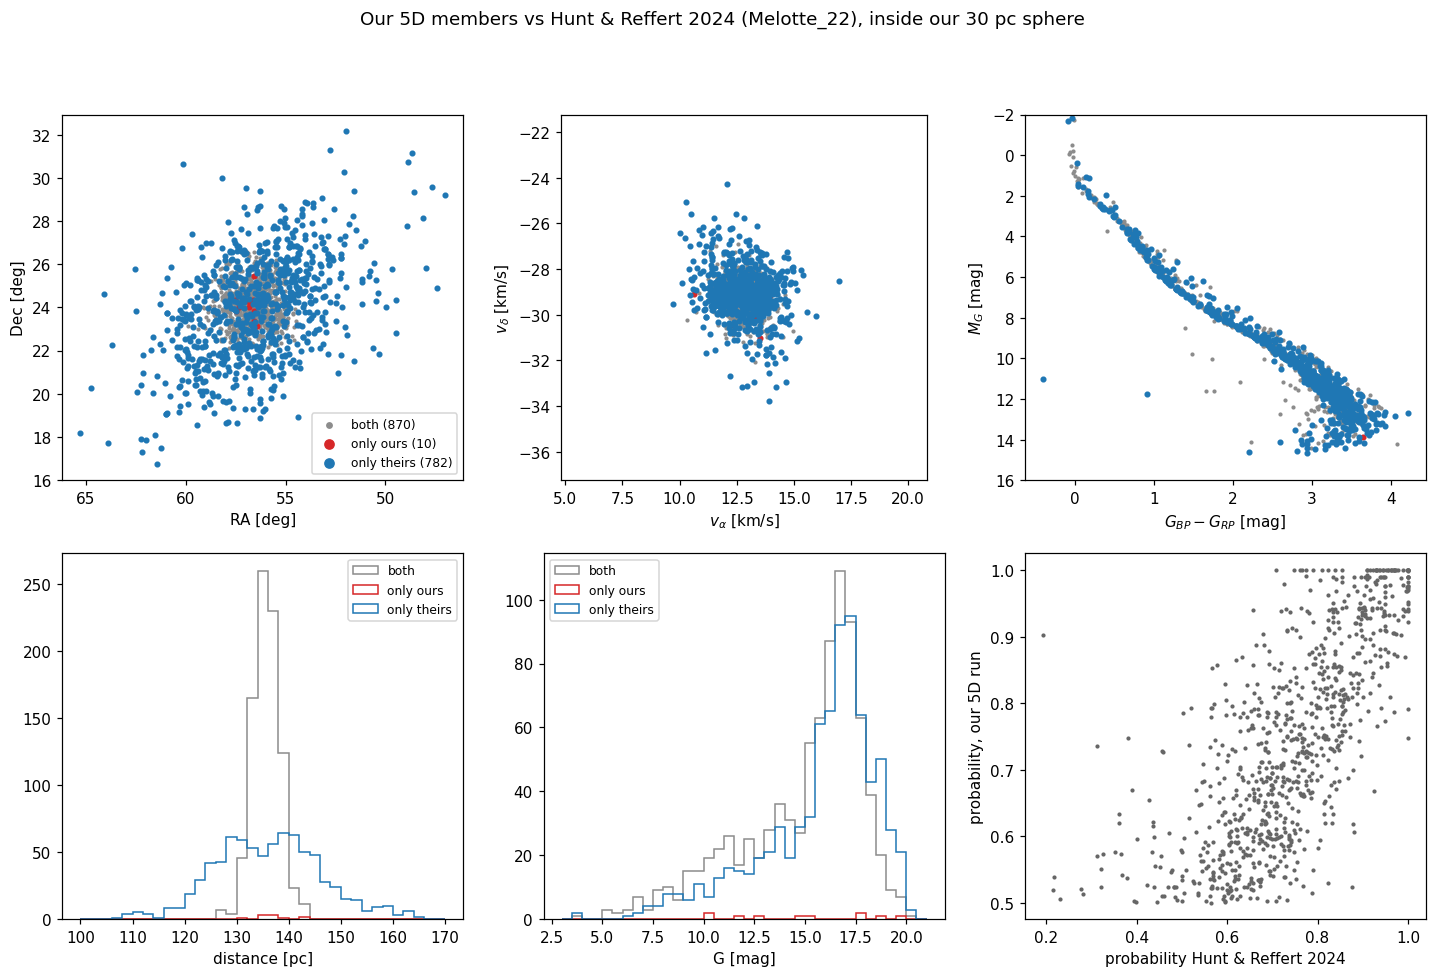

In [14]:
# ---- Funnel: where are their members relative to our sample? ----
in_dl = hr["source_id"].isin(df["source_id"])
in_sph = hr["source_id"].isin(sph["source_id"])
hr_sep = SkyCoord(hr["hr_ra"].to_numpy() * u.deg, hr["hr_dec"].to_numpy() * u.deg).separation(
    SkyCoord(PLEIADES_RA * u.deg, PLEIADES_DEC * u.deg)).deg
reason = np.where(in_sph, "in our sphere",
         np.where(in_dl, "downloaded, outside the sphere",
         np.where(hr_sep > CONE_RADIUS_DEG, "outside our cone", "not downloaded (parallax window or precision)")))
funnel = pd.Series(reason).value_counts()
print(f"{HR_LABEL} members of {HR_NAME}: {len(hr):,}")
print(funnel.to_string())
nd = reason == "not downloaded (parallax window or precision)"
if "hr_gmag" in hr and nd.any():
    print(f"Median G of the not downloaded ones: {hr.loc[nd, 'hr_gmag'].median():.1f} "
          f"(of those in the sphere: {hr.loc[in_sph, 'hr_gmag'].median():.1f})")

# ---- Four-field tables inside the common domain ----
hr_ids = set(hr["source_id"])
hr_rt_ids = set(hr.loc[hr["hr_in_rt"], "source_id"]) if "hr_in_rt" in hr else set()
hr_rj_ids = set(hr.loc[hr["hr_in_rj"], "source_id"]) if "hr_in_rj" in hr else set()
sph["hr_member"] = sph["source_id"].isin(hr_ids)
sph["hr_in_rt"] = sph["source_id"].isin(hr_rt_ids)
sph["hr_in_rj"] = sph["source_id"].isin(hr_rj_ids)

rows = []
for run in ("mem_5d", "mem_3d"):
    ours = sph[run].to_numpy()
    for ref_name, theirs in [("all their members", sph["hr_member"].to_numpy()),
                             ("their members inside r_J", sph["hr_in_rj"].to_numpy()),
                             ("their members inside r_t", sph["hr_in_rt"].to_numpy())]:
        if ref_name != "all their members" and not theirs.any():
            continue
        both = (ours & theirs).sum()
        rows.append(dict(our_run=run, reference=ref_name, ours=int(ours.sum()), theirs=int(theirs.sum()),
                         both=int(both), only_ours=int((ours & ~theirs).sum()), only_theirs=int((~ours & theirs).sum()),
                         recall=both / max(theirs.sum(), 1), agreement=both / max(ours.sum(), 1)))
cmp = pd.DataFrame(rows)
print("\nInside the common domain (stars in our sphere):")
print(cmp.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

# ---- Where do the disagreements sit? ----
ours, theirs = sph["mem_5d"].to_numpy(), sph["hr_member"].to_numpy()
grp = {"both": ours & theirs, "only ours": ours & ~theirs, "only theirs": ~ours & theirs}
desc_rows = []
for name, g in grp.items():
    s = sph[g]
    desc_rows.append(dict(group=name, n=int(g.sum()), median_G=s["phot_g_mean_mag"].median(),
                          median_sep_deg=s["sep_deg"].median(), median_r_centre=s["r_centre"].median(),
                          median_prob_ours=s["prob_5d"].median(), median_freq=s["freq_5d"].median(),
                          in_our_cluster_any_p=(s["lab_5d"] == pl5).mean() if pl5 is not None else np.nan,
                          frac_binary_flag=s["probable_binary"].mean()))
print("\n5D run vs all their members:")
print(pd.DataFrame(desc_rows).to_string(index=False, float_format=lambda v: f"{v:.2f}"))

fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
colors = {"both": "0.55", "only ours": "tab:red", "only theirs": "tab:blue"}
for name, g in grp.items():
    kw = dict(s=3 if name == "both" else 9, color=colors[name], label=f"{name} ({int(g.sum())})")
    axes[0, 0].scatter(sph.loc[g, "ra"], sph.loc[g, "dec"], **kw)
    axes[0, 1].scatter(sph.loc[g, "v_ra"], sph.loc[g, "v_dec"], **kw)
    axes[0, 2].scatter(sph.loc[g, "bp_rp"], sph.loc[g, "mg"], **kw)
    axes[1, 0].hist(sph.loc[g, "dist_pc"], bins=np.arange(100, 172, 2), histtype="step", color=colors[name], label=name)
    axes[1, 1].hist(sph.loc[g, "phot_g_mean_mag"], bins=np.arange(3, 21.5, 0.5), histtype="step", color=colors[name], label=name)
axes[0, 0].invert_xaxis(); axes[0, 0].set_xlabel("RA [deg]"); axes[0, 0].set_ylabel("Dec [deg]"); axes[0, 0].legend(fontsize=8, markerscale=2)
vr = sph.loc[ours, ["v_ra", "v_dec"]].median()
axes[0, 1].set_xlim(vr["v_ra"] - 8, vr["v_ra"] + 8); axes[0, 1].set_ylim(vr["v_dec"] - 8, vr["v_dec"] + 8)
axes[0, 1].set_aspect("equal"); axes[0, 1].set_xlabel(r"$v_{\alpha}$ [km/s]"); axes[0, 1].set_ylabel(r"$v_{\delta}$ [km/s]")
axes[0, 2].set_ylim(16, -2); axes[0, 2].set_xlabel(r"$G_{BP}-G_{RP}$ [mag]"); axes[0, 2].set_ylabel(r"$M_G$ [mag]")
axes[1, 0].set_xlabel("distance [pc]"); axes[1, 0].legend(fontsize=8)
axes[1, 1].set_xlabel("G [mag]"); axes[1, 1].legend(fontsize=8)
if "hr_prob" in hr:
    both_ids = sph.loc[grp["both"], ["source_id", "prob_5d"]].merge(hr[["source_id", "hr_prob"]], on="source_id")
    axes[1, 2].scatter(both_ids["hr_prob"], both_ids["prob_5d"], s=3, color="0.4")
    axes[1, 2].set_xlabel(f"probability {HR_LABEL}"); axes[1, 2].set_ylabel("probability, our 5D run")
else:
    axes[1, 2].set_axis_off()
fig.suptitle(f"Our 5D members vs {HR_LABEL} ({HR_NAME}), inside our {SPHERE_RADIUS:.0f} pc sphere")
fig.savefig(FIG / "02_hunt_reffert_comparison.png")
plt.show()

## 12. Colour-magnitude diagram of the members

**What.** Absolute magnitude M_G against colour BP-RP for the 5D members. The colour cuts of notebook 01 (G flux S/N > 50, BP and RP flux S/N > 20, |C\*| < 3 sigma) are applied *here only*, for the figure. Flagged binaries are highlighted. A simple binary test: a running median through the members defines the sequence, and we compare the share of flagged stars well above it (more than 0.35 mag brighter, where unresolved binaries sit, up to 0.75 mag for equal masses) with the share on it.

**Why.** If the flag really marks binaries, flagged stars should prefer the binary sequence. This is an independent check of the flag, using photometry instead of astrometry.

**Cost.** The colour cuts remove some faint and crowded stars from the figure only. M_G uses the individual parallaxes without extinction (the Pleiades have little, A_V of about 0.1 to 0.2 mag) and without zero-point correction (notebook 03).

**What to look for.** A narrow main sequence with a second, brighter sequence above it; M dwarfs bending upwards at the red end (they are still contracting at this age); few or no stars far off. Flagged stars should be over-represented above the sequence.

Members with good photometry: 682 of 880
Flagged share above the sequence (> 0.35 mag brighter): 47.4 % of 38
Flagged share on the sequence (within 0.2 mag):        5.2 % of 388


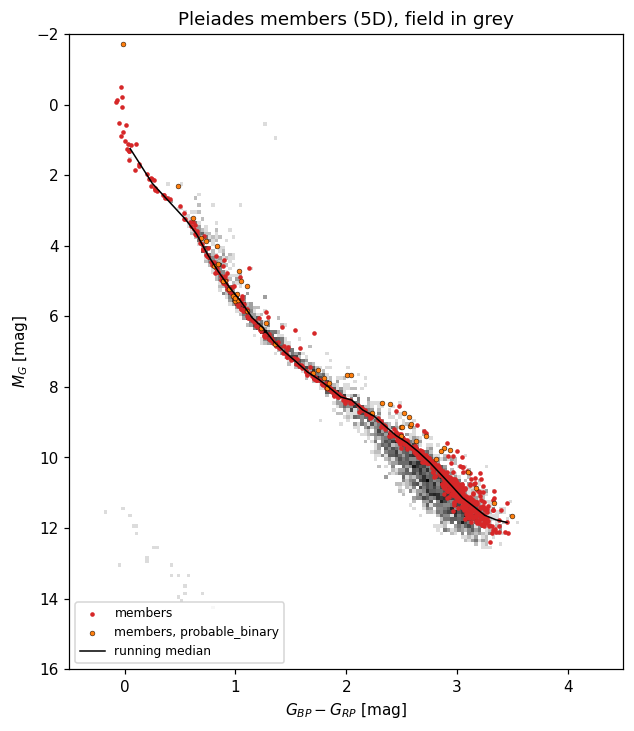

In [15]:
sph["c_star"] = bp_rp_excess_corrected(sph["phot_bp_rp_excess_factor"], sph["bp_rp"])
phot_ok = ((sph["phot_g_mean_flux_over_error"] > 50)
           & (sph["phot_bp_mean_flux_over_error"] > 20) & (sph["phot_rp_mean_flux_over_error"] > 20)
           & (np.abs(sph["c_star"]) < 3 * sigma_c_star(sph["phot_g_mean_mag"]))).fillna(False)
sph["phot_ok"] = phot_ok
cm = sph[sph["mem_5d"] & phot_ok].copy()
print(f"Members with good photometry: {len(cm):,} of {int(sph['mem_5d'].sum()):,}")

# running median sequence in colour bins
edges = np.arange(0.0, 3.6, 0.1)
centres = 0.5 * (edges[1:] + edges[:-1])
med = np.array([cm.loc[cm["bp_rp"].between(a, b), "mg"].median() if cm["bp_rp"].between(a, b).sum() >= 5 else np.nan
                for a, b in zip(edges[:-1], edges[1:])])
ok = np.isfinite(med)
cm["d_seq"] = cm["mg"] - np.interp(cm["bp_rp"], centres[ok], med[ok])
rng_col = cm["bp_rp"].between(0.3, 3.0)
above = rng_col & (cm["d_seq"] < -0.35)
on = rng_col & (cm["d_seq"].abs() < 0.2)
print(f"Flagged share above the sequence (> 0.35 mag brighter): {100 * cm.loc[above, 'probable_binary'].mean():.1f} % of {int(above.sum())}")
print(f"Flagged share on the sequence (within 0.2 mag):        {100 * cm.loc[on, 'probable_binary'].mean():.1f} % of {int(on.sum())}")

fig, ax = plt.subplots(figsize=(6.5, 7.5))
ok_all = sph["bp_rp"].notna() & phot_ok
ax.hist2d(sph.loc[ok_all, "bp_rp"], sph.loc[ok_all, "mg"], bins=(160, 180), range=((-0.5, 4.5), (-2, 16)),
          norm=LogNorm(), cmap="Greys", cmin=1)
ax.scatter(cm.loc[~cm["probable_binary"], "bp_rp"], cm.loc[~cm["probable_binary"], "mg"], s=4, color="tab:red", label="members")
ax.scatter(cm.loc[cm["probable_binary"], "bp_rp"], cm.loc[cm["probable_binary"], "mg"], s=10, color="tab:orange",
           edgecolor="k", lw=0.3, label="members, probable_binary")
ax.plot(centres[ok], med[ok], "k-", lw=1, label="running median")
ax.set_ylim(16, -2); ax.set_xlim(-0.5, 4.5)
ax.set_xlabel(r"$G_{BP}-G_{RP}$ [mag]"); ax.set_ylabel(r"$M_G$ [mag]"); ax.legend(fontsize=8, loc="lower left")
ax.set_title("Pleiades members (5D), field in grey")
fig.savefig(FIG / "02_members_cmd.png")
plt.show()

## 13. Save the result

All stars of the sphere are saved with their membership columns (not only the members), so that notebooks 03 and 04 can choose the member definition themselves and repeat the sensitivity checks:

| Column | Meaning |
|---|---|
| `mem_5d`, `prob_5d`, `lab_5d` | main run: member yes/no, HDBSCAN probability, cluster label |
| `mem_3d`, `prob_3d`, `lab_3d` | comparison run in 3D |
| `mem_5d_noflag` | run B without flagged stars (flagged stars are always False here) |
| `freq_5d` | member frequency in the redraws |
| `hr_member`, `hr_in_rt`, `hr_in_rj` | member of Hunt & Reffert; inside their King tidal radius r_t; inside their Jacobi radius r_J |
| `probable_binary`, `six_param`, `phot_ok` | flags; `phot_ok` = colour cuts passed |

In [16]:
OUT = config.PROCESSED / "01-02_pleiades_members.fits"
keep_cols = ["source_id", "ra", "dec", "l", "b", "parallax", "parallax_error", "pmra", "pmra_error",
             "pmdec", "pmdec_error", "parallax_pmra_corr", "parallax_pmdec_corr", "pmra_pmdec_corr",
             "ruwe", "astrometric_params_solved", "ipd_frac_multi_peak",
             "phot_g_mean_mag", "phot_bp_mean_mag", "phot_rp_mean_mag", "bp_rp",
             "phot_g_mean_flux_over_error", "phot_bp_mean_flux_over_error", "phot_rp_mean_flux_over_error",
             "phot_bp_rp_excess_factor", "c_star", "radial_velocity", "radial_velocity_error",
             "dist_pc", "x", "y", "z", "v_ra", "v_dec", "r_centre", "mg",
             "probable_binary", "six_param", "phot_ok",
             "lab_5d", "prob_5d", "mem_5d", "lab_3d", "prob_3d", "mem_3d", "mem_5d_noflag", "freq_5d",
             "hr_member", "hr_in_rt", "hr_in_rj"]
out = Table.from_pandas(sph[keep_cols])
out.meta = {"SPHERE": SPHERE_RADIUS, "MCS": MIN_CLUSTER_SIZE, "MS": MIN_SAMPLES, "SELECT": SELECTION,
            "PROBMIN": PROB_MIN, "NDRAWS": N_DRAWS, "HRCAT": HR_LABEL}
out.write(OUT, overwrite=True)
print(f"Saved {len(out):,} stars ({int(sph['mem_5d'].sum()):,} members, 5D) to {OUT}")

Saved 9,631 stars (880 members, 5D) to H:\Astronomie\data\processed\01-02_pleiades_members.fits


## 14. Summary and next steps

*Filled in after the first run, together with Claude. Each prediction from the top of the notebook gets a line: confirmed, or wrong and why.*

**Next (notebook 03):** cluster distance from the ensemble parallax of the members, with and without the parallax zero-point correction (Lindegren et al. 2021), compared with 136.2 +/- 1.2 pc (VLBI, Melis et al. 2014).